Numerical differentiation 

This is the code for the discretization of the differentiation problem by a matrix A
$$y(t) = Kx(t) = \int_0^t x(s) \; \mathrm ds$$

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# True solution x(s) and data y(s)
y = lambda s: s * np.exp(-s)
x = lambda s: np.exp(-s) * (1 - s)

# Grid initialization
N = 256
h = 1 / N
s = np.linspace(0, 1 - h, N)

# Evaluate x on grid
xvec = x(s)

# Matrix A: left-point quadrature rule (lower triangular matrix)
A = np.tril(np.ones((N, N))) * h

# Compute yvec = A * xvec
yvec = A @ xvec


Noise level: 0.036107849523450766
Relative error: 8.498044780736677


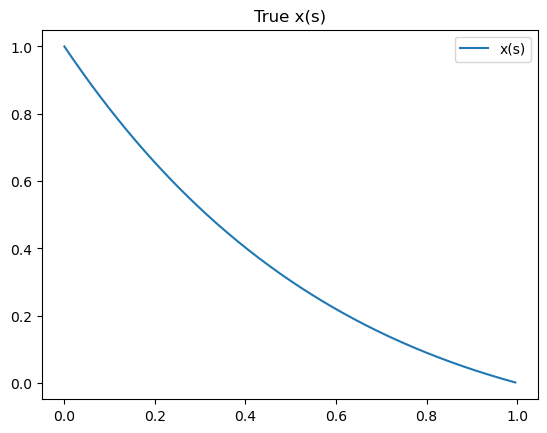

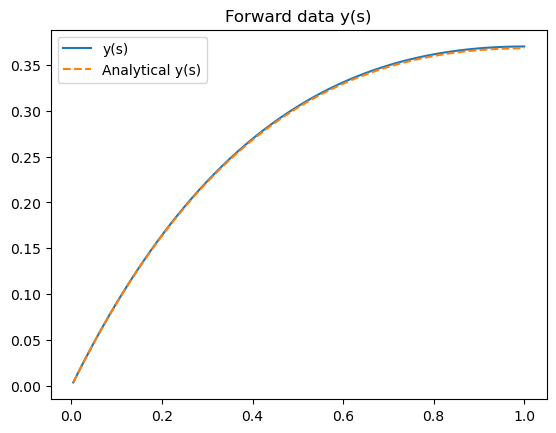

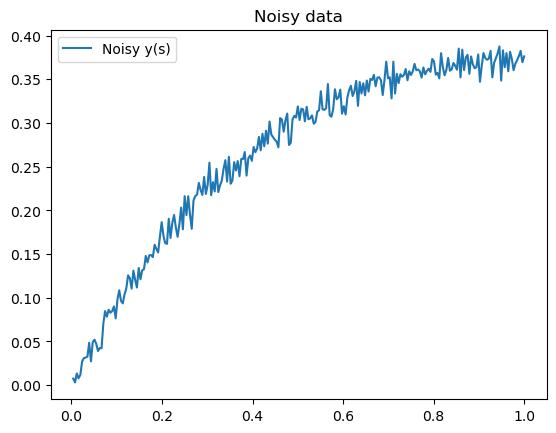

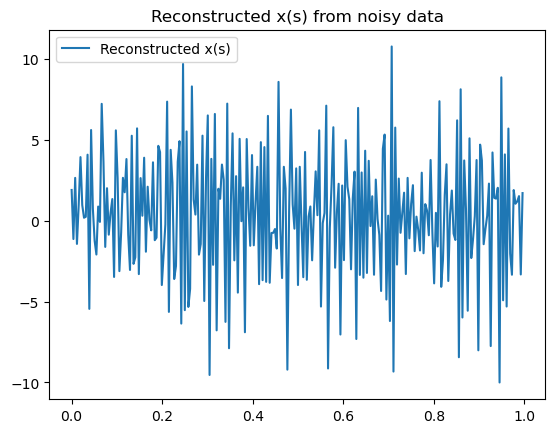

In [14]:
#Simple experiment with numerical differentiation
# Add noise
noise = 0.01 * np.random.randn(N)
yvecnoise = yvec + noise
noiselevel = np.linalg.norm(noise) / np.linalg.norm(yvec)
print("Noise level:", noiselevel)

# Naive inverse solution (commented out in original)
xvecrecon = np.linalg.solve(A, yvecnoise)

# Relative error (if inverse is computed)
relerror = np.linalg.norm(xvec - xvecrecon) / np.linalg.norm(xvec)
print("Relative error:", relerror)

# Optional plots
plt.figure()
plt.plot(s, xvec, label='x(s)')
plt.legend()
plt.title('True x(s)')
plt.show()

plt.figure()
plt.plot(s + h, yvec, label='y(s)')
plt.plot(s + h, y(s + h), '--', label='Analytical y(s)')
plt.legend()
plt.title('Forward data y(s)')
plt.show()

plt.figure()
plt.plot(s + h, yvecnoise, label='Noisy y(s)')
plt.legend()
plt.title('Noisy data')
plt.show()

plt.figure()
plt.plot(s, xvecrecon, label='Reconstructed x(s)')
plt.legend()
plt.title('Reconstructed x(s) from noisy data')
plt.show()


Abel problem

Below is a code for approximating the forward Abel problem by a matrix A
$$ y(t) = Kx(t) =\int_0^t \frac{x(s)}{\sqrt{t-s}}\;\mathrm ds

In [2]:
import numpy as np
from scipy.special import beta

# Abel integral operator approximation
# Problem: Approximate Kx(t) = ∫₀ᵗ x(s)/√(t-s) ds
# using numerical quadrature on offset s and t grids to avoid the singularity.
# Translated from MATLAB by Kim Knudsen (2024)

# Set number of discretization points
N = 256
h = 1 / N  # grid spacing

# Exact solutions
nu = 0
x = lambda s: s**nu
y = lambda t: t**(nu+1/2)*beta(1+nu,1/2)

# Grid initialization
N = 512
h = 1 / N

# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

# A now approximates the Abel integral operator

# testing

# Evaluate x and y on grid
xvec = x(svec)
xvec= xvec.reshape(-1,1)
yvec = y(tvec)

# Compare to Ax
Ax = A @ xvec

print(np.linalg.norm(yvec-Ax)/np.linalg.norm(yvec))


0.018881586973846735


Heat problem

This code approximtaes the forward heat problem by a matrix A. We use FFT and need to take care of periodic extensions (the problem is formulated with zero bdr. conditions, therefore the zero padding)

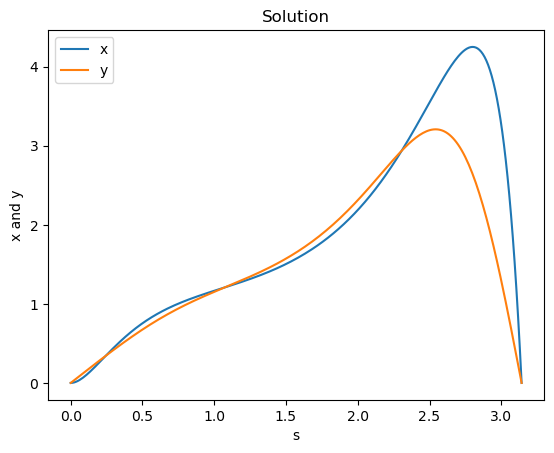

Relative error: 0.27765161260413995


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
m = 11
L = np.pi  # Length of the interval
N = 2**8   # Number of spatial points
ds = L / N  # Spatial step size
s = np.linspace(0, L, N + 1)  # Spatial grid

# Terminal time
T = 0.05

# Initial condition
u0 = s * np.sin(s) * np.exp((s - np.pi / 2)**2)  # Example initial condition
# u0 = np.sin(m * s)
x0 = u0

# Heat operator function
def HF(x0, T):
    N = len(x0) - 1
    k = np.fft.fftshift(np.arange(-N, N))  # Wave numbers

    # Odd extension to enforce sine series
    x = x0[1:-1]
    x_ext = np.concatenate(([0], x, [0], -x[::-1]))

    # FFT and time evolution
    x_hat = np.fft.fft(x_ext)
    x_hatT = x_hat * np.exp(-k**2 * T)
    xend = np.fft.ifft(x_hatT)

    return np.real(xend[:N+1])

# Compute terminal distribution
y = HF(x0, T)

# Plot
plt.plot(s, x0, label='x')
plt.plot(s, y, label='y')
plt.xlabel('s')
plt.ylabel('x and y')
plt.legend()
plt.title('Solution')
plt.show()

# Error norm - estimate the error against the true solution
error = np.linalg.norm(np.exp(-m**2 * T) * x0 - y) / np.linalg.norm(x0)
print("Relative error:", error)

# Compute matrix A
A = np.zeros((N + 1, N + 1))
Id = np.eye(N + 1)

for kk in range(N):
    A[:, kk] = HF(Id[:, kk], T)

# A is now the matrix representation of the heat operator


Blurring problem

This is the Philips test problem that approximates by a matrix A a blurring

In [ ]:
import numpy as np
from scipy.linalg import toeplitz

# Number of points on interval (-6,6); n/4 must be a positive integer
n = 2**8

# Setup
h = 12 / n
n4 = n // 4
r1 = np.zeros(n)

# Cosine values for the formula
c = np.cos(np.arange(-1, n4 + 1) * 4 * np.pi / n)

# Fill in the first n/4 entries
r1[:n4] = h + 9 / (h * np.pi**2) * (2 * c[1:n4 + 1] - c[:n4] - c[2:n4 + 2])

# Middle entry
r1[n4] = h / 2 + 9 / (h * np.pi**2) * (np.cos(4 * np.pi / n) - 1)

# Construct Toeplitz matrix
A = toeplitz(r1)

#Test the solution

